# **MINI PROJECT PCD KEL 3**
DETEKSI UANG KERTAS ASLI ATAU PALSU MENGGUNAKAN EKSTRAKSI FITUR WARNA, TEKSTUR, DAN TEPI BERBASIS METODE RULE-BASED

Nama dan NIM Anggota :
1. Yanaka Sofia Pardede (24031554065)
2. Shakyla Andhara Chandraningtyas (24031554199)
3. Annisa Ramadhani	 (24031554206)

Kelas : 2024B

# **IMPORT LIBRARY**

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

from skimage.feature import local_binary_pattern

# **LOAD DATASET**

## **Mount Google Drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Menentukan Path Dataset**

In [ ]:
drive.mount('/content/drive')
base_path = "/content/drive/Shareddrives/DATASET MINI PROJECT PCD KEL 3"
categories = ["uang asli", "uang palsu"]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Loading Dataset**

In [ ]:
data = []
labels = []

for category in categories:
    path = os.path.join(base_path, category)
    label = categories.index(category)

    for img_name in os.listdir(path):
        img_path = os.path.join(path, img_name)
        img = cv2.imread(img_path)

        if img is not None:
            img = cv2.resize(img, (256, 256))
            data.append(img)
            labels.append(label)

data = np.array(data)
labels = np.array(labels)

print("Jumlah data:", len(data))
print("Shape data:", data.shape)


Jumlah data: 120
Shape data: (120, 256, 256, 3)


## **Visualisasi Dataset**

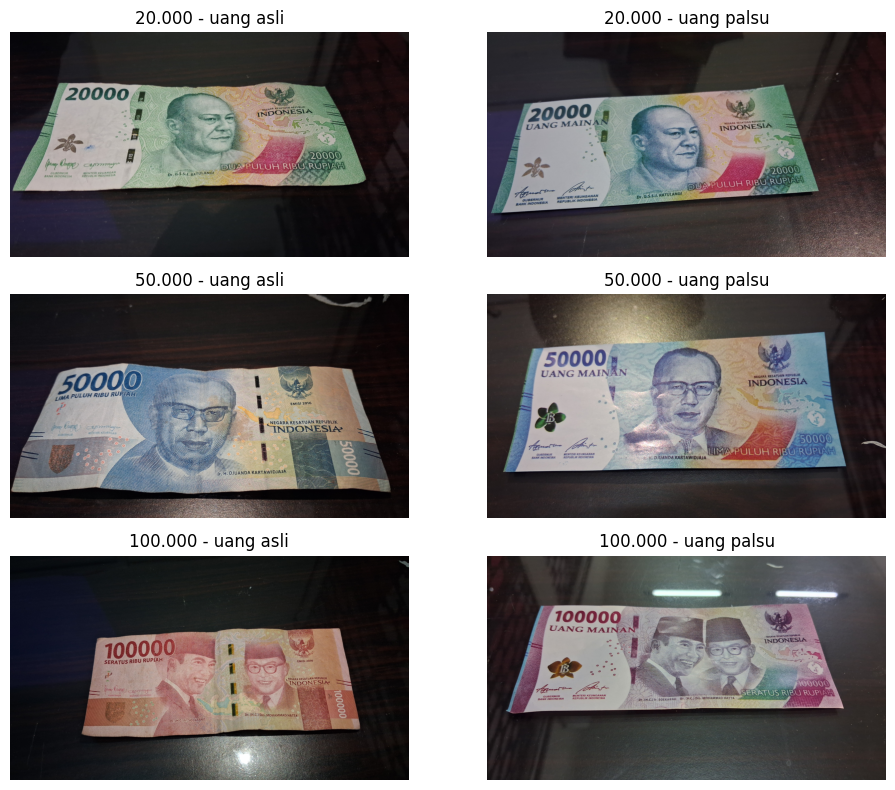

In [ ]:
targets = ["20.000", "50.000", "100.000"]

plt.figure(figsize=(10,8))
i = 1

for t in targets:
    for c in categories:
        path = os.path.join(base_path, c)

        file_found = None
        for f in os.listdir(path):
            if t in f:
                file_found = f
                break

        if file_found:
            img_path = os.path.join(path, file_found)
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            plt.subplot(3, 2, i)
            plt.imshow(img)
            plt.title(f"{t} - {c}")
            plt.axis("off")
            i += 1

plt.tight_layout()
plt.show()

# **PREPROCESSING**

## **Preprocessing Citra**

In [ ]:
gray_data = []

for img in data:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5,5), 0)
    gray_data.append(blur)

gray_data = np.array(gray_data)

## **Visualisasi Hasil Preprocessing**

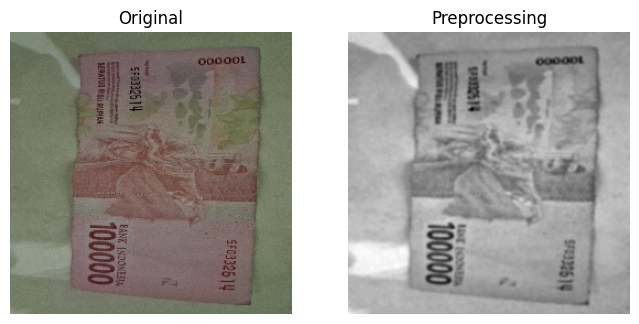

In [ ]:
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(data[0], cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gray_data[0], cmap='gray')
plt.title("Preprocessing")
plt.axis("off")

plt.show()

# **FEATURE EXTRACTION**

## **Color Histogram**

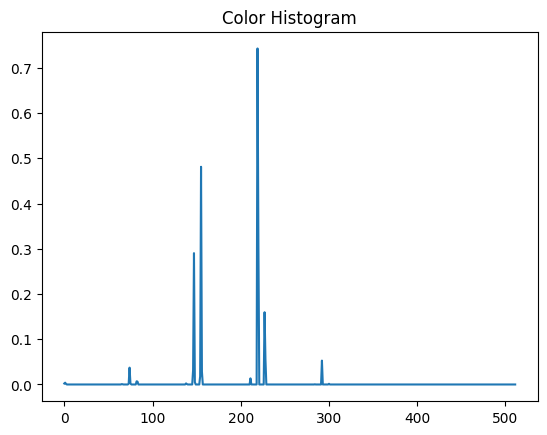

In [ ]:
def color_histogram(img):
    hist = cv2.calcHist([img], [0,1,2], None, [8,8,8], [0,256]*3)
    return cv2.normalize(hist, hist).flatten()

features_color = np.array([color_histogram(img) for img in data])

plt.plot(features_color[0])
plt.title("Color Histogram")
plt.show()

## **Texture (LBP)**

In [ ]:
def lbp_feature(img):
    lbp = local_binary_pattern(img, P=8, R=1, method='uniform')
    hist, _ = np.histogram(lbp.ravel(),
                           bins=np.arange(0, 10),
                           range=(0, 9))
    return hist

features_lbp = np.array([lbp_feature(img) for img in gray_data])

print("LBP sample:", features_lbp[0])

LBP sample: [  378  2117   826  8137 15387 17540  5824  4393 10934]


## **Egde (Canny)**

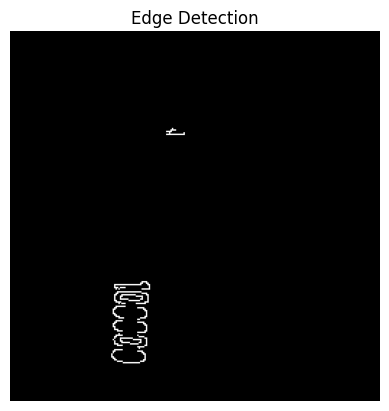

In [ ]:
def edge_feature(img):
    edges = cv2.Canny(img, 100, 200)
    density = np.sum(edges) / (img.shape[0] * img.shape[1])
    return np.array([density])

features_edge = np.array([edge_feature(img) for img in gray_data])

edges = cv2.Canny(gray_data[0], 100, 200)
plt.imshow(edges, cmap='gray')
plt.title("Edge Detection")
plt.axis('off')
plt.show()

# **CLASSIFICATION(rule-based)**

In [ ]:
def get_class_means(features, labels):
    class_0 = features[labels == 0]  # asli
    class_1 = features[labels == 1]  # palsu

    mean_0 = np.mean(class_0, axis=0)
    mean_1 = np.mean(class_1, axis=0)

    return mean_0, mean_1


def classify(features, labels):
    scaler = StandardScaler()
    features = scaler.fit_transform(features)

    mean_0, mean_1 = get_class_means(features, labels)

    y_pred = []

    for f in features:
        dist_0 = np.linalg.norm(f - mean_0)
        dist_1 = np.linalg.norm(f - mean_1)

        if dist_0 < dist_1:
            y_pred.append(0)
        else:
            y_pred.append(1)

    y_pred = np.array(y_pred)

    acc = accuracy_score(labels, y_pred)
    cm = confusion_matrix(labels, y_pred)

    return acc, cm, y_pred


# **EVALUATION**

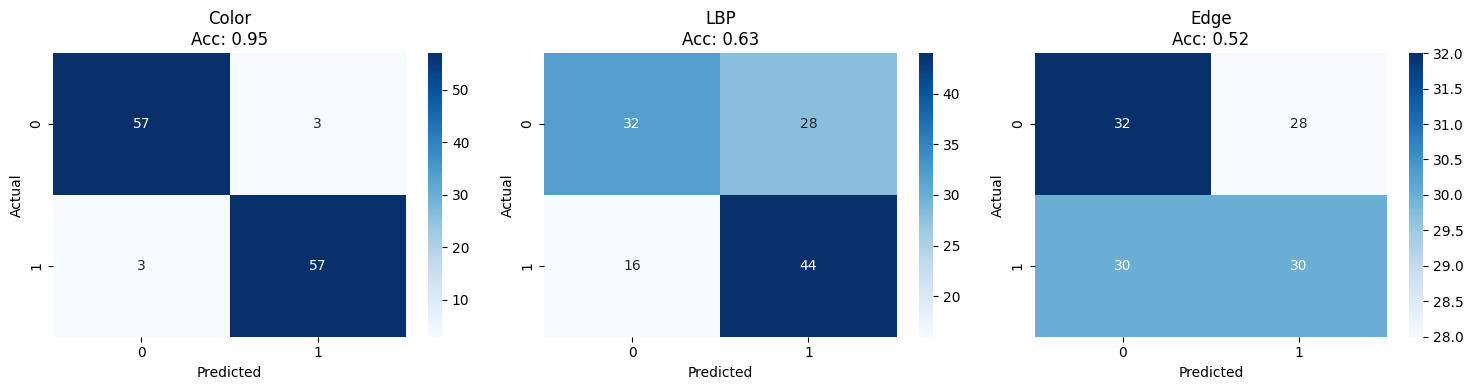

In [ ]:
acc_color, cm_color, y_pred_c = classify(features_color, labels)
acc_lbp, cm_lbp, y_pred_l = classify(features_lbp, labels)
acc_edge, cm_edge, y_pred_e = classify(features_edge, labels)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.heatmap(cm_color, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f"Color\nAcc: {acc_color:.2f}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_lbp, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title(f"LBP\nAcc: {acc_lbp:.2f}")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

sns.heatmap(cm_edge, annot=True, fmt='d', cmap='Blues', ax=axes[2])
axes[2].set_title(f"Edge\nAcc: {acc_edge:.2f}")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# **COMPARISON OF FEATURE EXTRACTION**

         Feature  Accuracy
0          Color  0.950000
1  Texture (LBP)  0.633333
2           Edge  0.516667


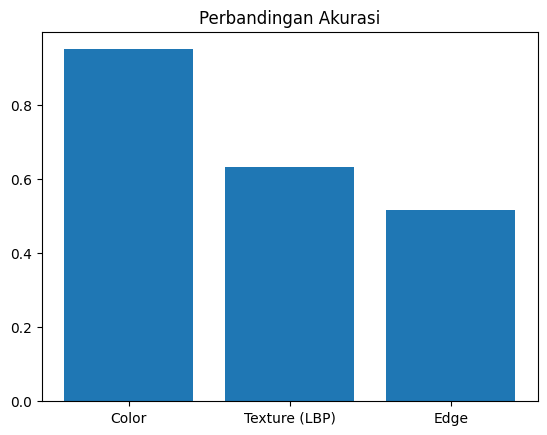

In [ ]:
results = pd.DataFrame({
    "Feature": ["Color", "Texture (LBP)", "Edge"],
    "Accuracy": [acc_color, acc_lbp, acc_edge]
})

print(results)

plt.bar(results["Feature"], results["Accuracy"])
plt.title("Perbandingan Akurasi")
plt.show()

# **FEATURE COMBINATION**


Combined Accuracy: 0.95


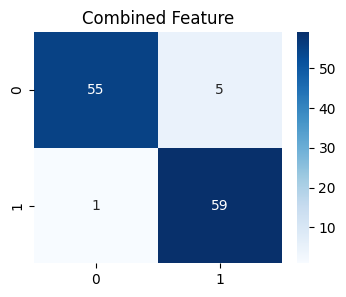

In [ ]:
X_combined = np.hstack([features_color, features_lbp, features_edge])

acc_comb, cm_comb, y_pred_comb = classify(X_combined, labels)

print("\nCombined Accuracy:", acc_comb)

plt.figure(figsize=(4,3))
sns.heatmap(cm_comb, annot=True, fmt='d', cmap='Blues')
plt.title("Combined Feature")
plt.show()

# **ERROR ANALYSIS**


=== ERROR ANALYSIS (COLOR) ===


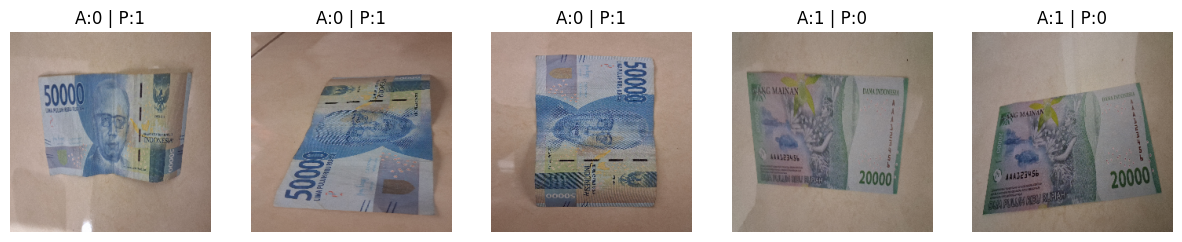

In [ ]:
def show_errors(images, labels, y_pred):
    wrong = np.where(labels != y_pred)[0]
    n = min(5, len(wrong))

    plt.figure(figsize=(15,3))

    for i in range(n):
        idx = wrong[i]

        plt.subplot(1, n, i+1)
        plt.imshow(cv2.cvtColor(images[idx], cv2.COLOR_BGR2RGB))
        plt.title(f"A:{labels[idx]} | P:{y_pred[idx]}")
        plt.axis('off')

    plt.show()


print("\n=== ERROR ANALYSIS (COLOR) ===")
show_errors(data, labels, y_pred_c)